# Step 5: Adding the mentor's pipeline to ours

**Paper:** S. R. Sreeja and D. Samanta, *Classification of multiclass motor imagery EEG signal using sparsity approach*, Neurocomputing 368 (2019) 133–145.

**Goal:** keep our pipeline (8–30 Hz FIR → 0–4 s → z-score → EEGNet) and **add** every technique from the paper, measuring how much each one changes **per-subject and average accuracy** on the standard protocol (train on session T, test on session E). The cross-subject result is reported too.

| Technique from the paper | How it was added | Where |
|---|---|---|
| Motor-area channel selection (around C3/C4) | EEGNet on 14 channels (E1); also tested in her classifier | §3, §2 |
| Her filter (Chebyshev type II, order 6) | replaces our FIR filter, same 8–30 Hz (E2) | §3 |
| Sub-bands (1, 2, 3, 6, 9) and CSP (10 filters); no-filter case | her classifier, all 3 cases | §2 |
| Short-segment segmentation (0.2 s, 0.5 s) | her classifier; for EEGNet as 2 s windows with trial-level averaging (E3) | §2, §3 |
| Wavelet energy (coif1, level 1), wavelet entropy | her classifier | §2 |
| Per-subject dictionary + OMP sparse representation, rules R1–R4 | her classifier, then **fused** with EEGNet | §2, §4 |

**Rules (fixed before running):** every choice uses **session T only** (leave-one-run-out cross-validation, 9 subjects × 6 folds). An addition is **kept only if it raises mean CV accuracy by ≥ 0.5 percentage points**. Session E is used once, for testing.

All runs were executed by `experiments/run_mentor.py` (orchestrated by `experiments/overnight.py`), with every result in `results/mentor/` and every model in `checkpoints/mentor/`. This notebook only loads and analyses them.

In [1]:
import json
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
from data import CLASS_NAMES, SUBJECTS
from plots import per_class_recall, plot_confusion_grid, plot_recall_heatmap

R = ROOT / "results" / "mentor"
FIG = ROOT / "results" / "figures"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
J = lambda p: json.loads(Path(p).read_text())
summary = J(R / "summary.json")
RUN = np.repeat(np.arange(6), 48)
print("Overnight run status:", (ROOT / "results" / "overnight_status.txt").read_text().strip().splitlines()[-1])

Overnight run status: [2026-10-14 12:57:17] ALL DONE - results in results/mentor/summary.md


## 1. Implementation checks
`src/mentor_pipeline.py` implements the paper's pipeline. `tests/test_mentor_pipeline.py` checks it. The test output is shown below:
- wavelet energy of approximation + detail equals the signal energy
- segments never mix trials
- our batched OMP matches scikit-learn's reference OMP
- a known sparse code is recovered
- real-data labels match our main pipeline, and the filter removes low frequencies
- CSP is fitted on training trials only

In [2]:
import subprocess
out = subprocess.run([sys.executable, str(ROOT / "tests" / "test_mentor_pipeline.py")], capture_output=True, text=True)
print("\n".join(l for l in out.stdout.splitlines() if l.startswith(("ok", "ALL"))))

ok  wavelet energy: shape (5,20,44); energy(A)+energy(D) == energy(signal)
ok  segmentation: 4 s -> 20 x 0.2 s segments, each from its own trial and channel
ok  batched OMP == scikit-learn orthogonal_mp (max coefficient difference 1.5e-10)
ok  OMP: test vector built from 2 class-2 atoms is assigned to class 2 by R1-R4
ok  classifier on separable toy data: accuracy {'R1': np.float64(0.945), 'R2': np.float64(0.28), 'R3': np.float64(0.945), 'R4': np.float64(1.0)}  (0.3 ms/vector)
ok  real data: (288,14,1000), labels match main pipeline; <4 Hz power ratio raw 11.42 -> filtered 0.0023
ok  CSP: fitted on 240 training trials, 10 components applied to 48 held-out trials
ok  speed: dictionary 4800 atoms x 44 dims -> 0.3 ms per test segment (~0 s per fold of 960 segments)
ALL TESTS PASSED


## 2. Her classifier (wavelet energy + sparse representation)

### 2a. All settings, cross-validated inside session T (trial-level)
21 settings: 3 filtering cases × sub-bands × channel sets × segment lengths, plus the wavelet-entropy feature. Each is scored with rules R1–R4. A trial's 20 segment results are summed into one trial decision, because a wheelchair command is issued per trial.

In [3]:
sel = J(R / "sparse_selection.json")
rows = []
for name, t in sel["table"].items():
    c = t["config"]
    rows.append({"setting": name, "case": {"none": "3: no filter", "bp": "2: band-pass", "bp_csp": "1: band-pass + CSP"}[c["case"]],
                 "sub-bands": c["bands"] or "-", "channels": c["channels"], "segment (s)": c["seg"], "feature": c["feature"],
                 **{r: round(100 * t[r], 1) for r in ["R1", "R2", "R3", "R4"]}})
grid = pd.DataFrame(rows).sort_values("R4", ascending=False).reset_index(drop=True)
print(f"Chosen: {sel['chosen']} with rule {sel['rule']}: mean CV accuracy {100 * sel['cv_acc']:.1f}%")
grid

Chosen: bp_csp_b9_all_s2_energy with rule R4: mean CV accuracy 57.8%


,setting,case,sub-bands,channels,segment (s),feature,R1,R2,R3,R4
0,bp_csp_b9_all_s2_energy,1: band-pass + CSP,9,all,0.2,energy,50.6,35.8,50.5,57.8
1,bp_csp_b6_all_s2_energy,1: band-pass + CSP,6,all,0.2,energy,51.3,38.8,51.3,53.9
2,bp_csp_b3_all_s2_energy,1: band-pass + CSP,3,all,0.2,energy,46.8,36.2,47.4,50.2
3,bp_csp_b2_all_s2_energy,1: band-pass + CSP,2,all,0.2,energy,48.0,38.7,47.5,49.4
4,bp_csp_b1_all_s2_energy,1: band-pass + CSP,1,all,0.2,energy,46.1,40.6,45.5,46.3
5,bp_b6_all_s2_energy,2: band-pass,6,all,0.2,energy,35.5,27.5,35.0,38.4
6,bp_b9_all_s2_energy,2: band-pass,9,all,0.2,energy,34.7,26.0,34.3,38.4
7,bp_b2_all_s2_energy,2: band-pass,2,all,0.2,energy,35.6,30.1,35.6,37.0
8,bp_b2_motor_s2_energy,2: band-pass,2,motor,0.2,energy,35.5,31.1,34.8,36.6
9,bp_b6_motor_s2_energy,2: band-pass,6,motor,0.2,energy,33.2,27.0,33.4,35.9


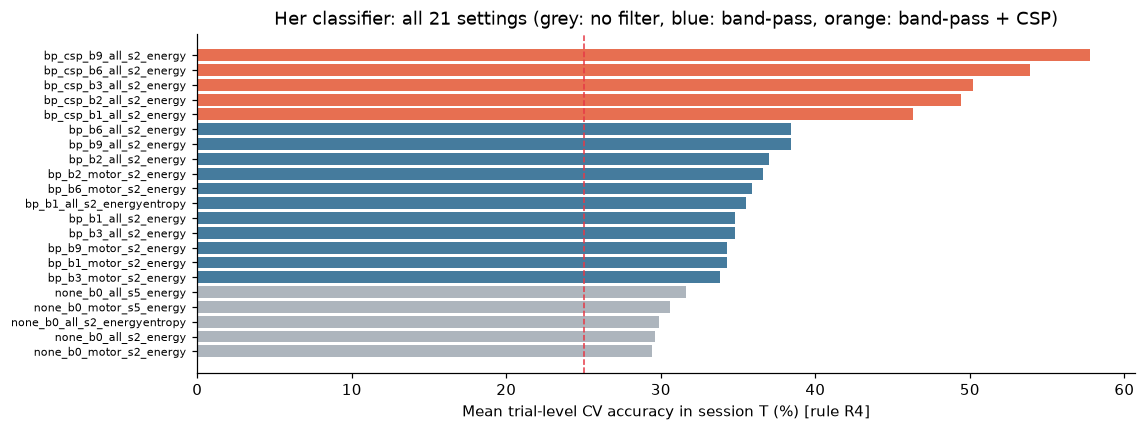

In [4]:
fig, ax = plt.subplots(figsize=(11, 4))
order = grid.sort_values("R4")
colors = order["case"].map({"3: no filter": "#adb5bd", "2: band-pass": "#457b9d", "1: band-pass + CSP": "#e76f51"})
ax.barh(order["setting"], order["R4"], color=colors)
ax.axvline(25, color="#e63946", ls="--", lw=1)
ax.set_xlabel("Mean trial-level CV accuracy in session T (%) [rule R4]")
ax.set_title("Her classifier: all 21 settings (grey: no filter, blue: band-pass, orange: band-pass + CSP)")
ax.tick_params(axis="y", labelsize=7)
fig.savefig(FIG / "05_sparse_settings_cv.png", bbox_inches="tight"); plt.show()

**Reading:** on our dataset, her classifier only works with band-pass **and CSP**. Without filtering it stays at chance (about 25–30%), and band-pass alone is weak. Her paper found the opposite on BCI III-IIIa, where filtering made little difference. Rule R4 (smallest class residual) is the best rule, as in her paper.

### 2b. Why the paper's numbers are much higher: the evaluation protocol
Her paper splits **segments** randomly into 10 folds, so segments of the same trial (and CSP filters fitted on all trials) appear in both training and testing. Here is the same classifier evaluated three ways.

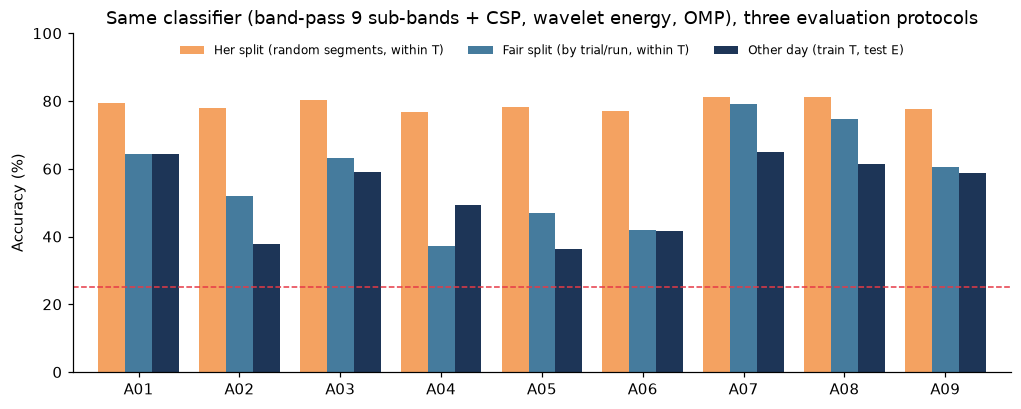

Her best setting from the paper (no filter, motor channels, 0.2 s) with her split: 27.4%


,"Her split (random segments, within T)","Fair split (by trial/run, within T)","Other day (train T, test E)"
A01,79.4,64.2,64.2
A02,78.0,52.1,37.8
A03,80.3,63.2,59.0
A04,76.9,37.2,49.3
A05,78.3,46.9,36.5
A06,76.9,42.0,41.7
A07,81.3,79.2,64.9
A08,81.1,74.7,61.5
A09,77.7,60.4,58.7
mean,78.9,57.8,52.6


In [5]:
p0 = J(R / "p0_extra.json")["bp_csp_b9_all_s2_energy"]
e_best = {s: J(R / "sparse_t2e" / sel["chosen"] / f"{s}.json")["acc"][sel["rule"]] for s in SUBJECTS}
cmp = pd.DataFrame({"Her split (random segments, within T)": {s: p0[s]["her_split_segment_acc"] for s in SUBJECTS},
                    "Fair split (by trial/run, within T)": {s: p0[s]["trial_level_cv_acc"] for s in SUBJECTS},
                    "Other day (train T, test E)": e_best}) * 100
cmp.loc["mean"] = cmp.mean()
ax = cmp.iloc[:-1].plot.bar(figsize=(11, 4), color=["#f4a261", "#457b9d", "#1d3557"], rot=0, width=0.8)
ax.axhline(25, color="#e63946", ls="--", lw=1); ax.set_ylim(0, 100); ax.set_ylabel("Accuracy (%)")
ax.set_title("Same classifier (band-pass 9 sub-bands + CSP, wavelet energy, OMP), three evaluation protocols")
ax.legend(frameon=False, fontsize=8, ncol=3, loc="upper center")
ax.figure.savefig(FIG / "05_protocol_comparison.png", bbox_inches="tight"); plt.show()
p0_none = np.mean([J(f)["segment_acc"] for f in (R / "sparse_p0" / "none_b0_motor_s2_energy").glob("*.json")])
print(f"Her best setting from the paper (no filter, motor channels, 0.2 s) with her split: {100 * p0_none:.1f}%")
cmp.round(1)

**Reading:** with her split, every subject scores about 77–81%, including A04, whose fair score is 37%. The split inflates accuracy by **about 21 points** on average (78.9% vs 57.8%), and testing on another day lowers it further, to 52.6%. Her best setting from the paper (no filter) does not work on our dataset even with her split (≈27%). The difference in dataset (BCI III-IIIa, 60 channels, 3 subjects) and in evaluation explains the gap to the paper's 91.8%.

## 3. Her techniques added to EEGNet (E1–E3)

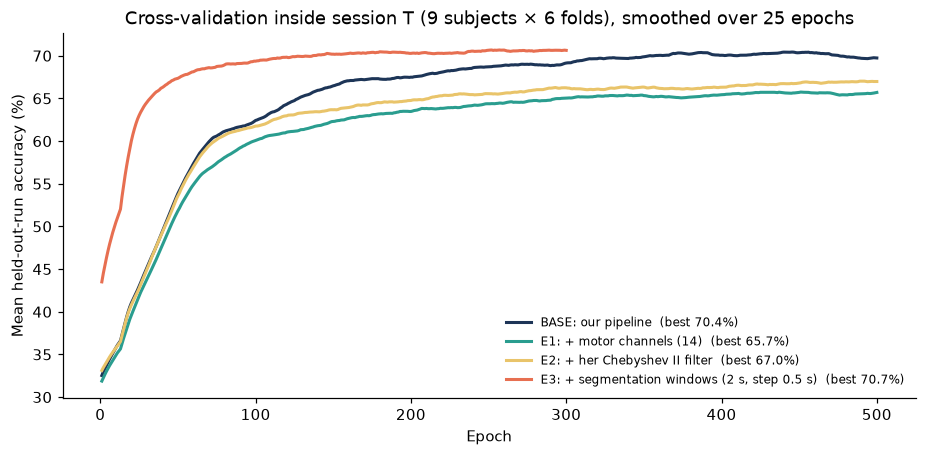

Kept additions: none  ->  final EEGNet pipeline: BASE
Check: BASE CV here 70.4% vs 70.5% in notebook 04 Phase 2 (same pipeline re-run), so the runner reproduces earlier results.


,CV accuracy (%),change vs BASE (pp),chosen epochs,kept (>= +0.5 pp)
BASE,70.43,0.0,446,False
E1,65.74,-4.69,451,False
E2,67.03,-3.4,491,False
E3,70.67,0.25,257,False


In [6]:
es = J(R / "eeg_selection.json")
def mean_curve(v):
    runs = [J(R / "eeg_cv" / v / f"{s}_run{r}.json") for s in SUBJECTS for r in range(1, 7)]
    c = np.mean([x["mon_acc"] for x in runs], 0) * 100
    return np.array([c[max(0, i - 12): i + 13].mean() for i in range(len(c))])
labels = {"BASE": "BASE: our pipeline", "E1": "E1: + motor channels (14)", "E2": "E2: + her Chebyshev II filter",
          "E3": "E3: + segmentation windows (2 s, step 0.5 s)"}
fig, ax = plt.subplots(figsize=(10, 4.3))
for v, col in zip(labels, ["#1d3557", "#2a9d8f", "#e9c46a", "#e76f51"]):
    c = mean_curve(v); ax.plot(np.arange(1, len(c) + 1), c, color=col, lw=2, label=f"{labels[v]}  (best {es['summary'][v]['cv_acc'] * 100:.1f}%)")
ax.set_xlabel("Epoch"); ax.set_ylabel("Mean held-out-run accuracy (%)")
ax.set_title("Cross-validation inside session T (9 subjects × 6 folds), smoothed over 25 epochs")
ax.legend(frameon=False, fontsize=8, loc="lower right")
fig.savefig(FIG / "05_eegnet_variants_cv.png", bbox_inches="tight"); plt.show()

dec = pd.DataFrame({v: {"CV accuracy (%)": round(100 * es["summary"][v]["cv_acc"], 2),
                        "change vs BASE (pp)": round(100 * (es["summary"][v]["cv_acc"] - es["summary"]["BASE"]["cv_acc"]), 2),
                        "chosen epochs": es["summary"][v]["best_epochs"],
                        "kept (>= +0.5 pp)": v in es["kept"]} for v in labels}).T
print(f"Kept additions: {es['kept'] or 'none'}  ->  final EEGNet pipeline: {es['final']}")
print("Check: BASE CV here 70.4% vs 70.5% in notebook 04 Phase 2 (same pipeline re-run), so the runner reproduces earlier results.")
dec

**Reading:** motor-channel selection (E1) and her filter (E2) **lower** accuracy for EEGNet. EEGNet learns its own spatial filters from all 22 channels, and the Chebyshev filter's steep edges remove part of the 8–30 Hz band. Segmentation windows (E3) improve it slightly (+0.3 pp), but this is below the +0.5 pp rule fixed in advance, so no EEGNet addition was kept.

## 4. Fusion: EEGNet + her classifier

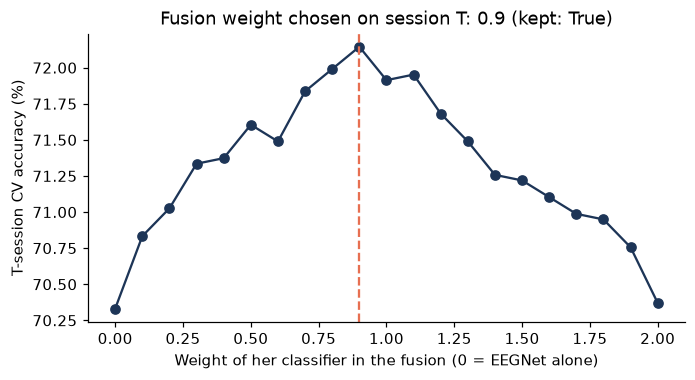

CV accuracy: EEGNet alone 70.33% -> fused 72.15%


In [7]:
fu = summary["fusion"]
pairs = sorted((float(k), 100 * v) for k, v in fu["cv_acc_by_weight"].items())
w, a = [p[0] for p in pairs], [p[1] for p in pairs]
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.plot(w, a, "o-", color="#1d3557"); ax.axvline(fu["weight"], color="#e76f51", ls="--")
ax.set_xlabel("Weight of her classifier in the fusion (0 = EEGNet alone)"); ax.set_ylabel("T-session CV accuracy (%)")
ax.set_title(f"Fusion weight chosen on session T: {fu['weight']} (kept: {fu['kept']})")
fig.savefig(FIG / "05_fusion_weight.png", bbox_inches="tight"); plt.show()
print(f"CV accuracy: EEGNet alone {a[0]:.2f}% -> fused {max(a):.2f}%")

## 5. Results on session E: per subject and average
Every row is trained on all 288 T trials and tested once on the 288 E trials. *Single* is the mean over 5 random seeds. *Ensemble* averages the 5 seeds' predicted probabilities.

In [8]:
t = summary["t2e"]
names = {"BASE": "Our pipeline (EEGNet)", "E1": "+ motor channels", "E2": "+ her Chebyshev filter", "E3": "+ segmentation windows",
         "SPARSE": "Her classifier alone (best setting)", "FINAL_FUSED": "EEGNet + her classifier (fused)"}
rows = []
for k, lab in names.items():
    for kind in ("single", "ensemble"):
        if kind in t[k]:
            rows.append({"pipeline": lab, "type": kind, **{s: round(100 * t[k][kind][s], 1) for s in SUBJECTS},
                         "mean": round(100 * t[k][kind]["mean"], 2)})
res = pd.DataFrame(rows)
res.to_csv(ROOT / "results" / "mentor_pipeline_results.csv", index=False)
res

,pipeline,type,A01,A02,A03,A04,A05,A06,A07,A08,A09,mean
0,Our pipeline (EEGNet),single,81.5,46.9,89.7,59.5,54.4,49.9,70.8,78.8,82.3,68.20
1,Our pipeline (EEGNet),ensemble,87.2,48.6,92.7,67.4,61.8,60.8,78.5,80.2,84.7,73.53
2,+ motor channels,single,78.4,46.9,87.5,50.9,49.3,47.8,69.1,76.0,80.8,65.21
3,+ motor channels,ensemble,82.3,50.7,89.2,57.6,56.6,51.0,75.0,77.1,81.9,69.06
4,+ her Chebyshev filter,single,79.2,49.7,88.3,56.9,35.0,48.5,71.2,76.9,79.7,65.04
5,+ her Chebyshev filter,ensemble,84.4,54.5,88.9,62.5,40.6,53.5,76.7,80.2,81.9,69.25
6,+ segmentation windows,single,83.6,48.5,85.6,61.5,54.6,50.1,77.0,77.2,81.5,68.84
7,+ segmentation windows,ensemble,87.5,50.7,87.8,69.1,60.4,56.6,79.5,81.2,85.4,73.15
8,Her classifier alone (best setting),single,64.2,37.8,59.0,49.3,36.5,41.7,64.9,61.5,58.7,52.62
9,EEGNet + her classifier (fused),single,82.3,48.1,88.5,64.5,55.3,51.0,75.0,81.5,84.7,70.10


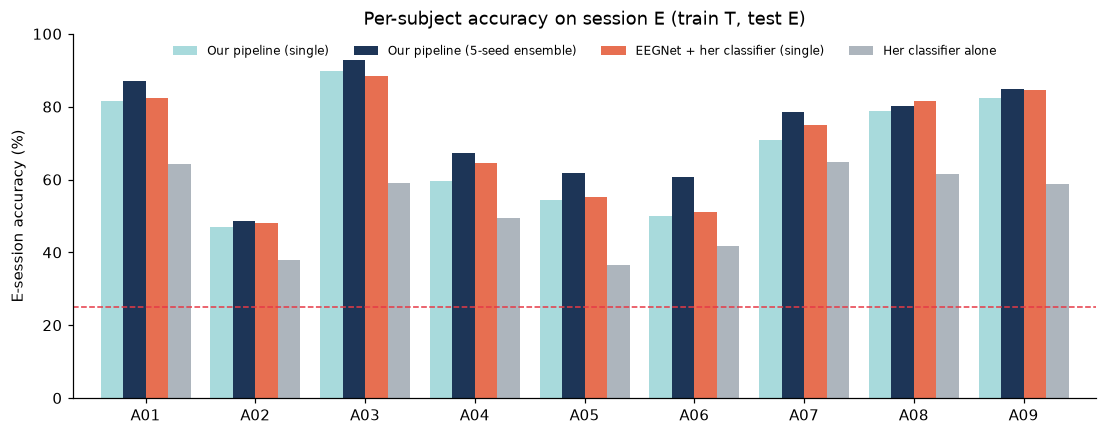

,mean accuracy (%)
"Our pipeline, 1 model",68.20
"Our pipeline, 5-seed ensemble",73.53
"EEGNet + her classifier, 1 model",70.10
"EEGNet + her classifier, ensemble",73.07
Her classifier alone,52.62
Nzakuna 2025: MCD (1 network),71.14
Nzakuna 2025: EMCD (15 networks),75.35
Nzakuna 2025: LEMC-FTDB,80.40


In [9]:
ref = pd.read_csv(ROOT / "results" / "reference_nzakuna2025_table2.csv").set_index("subject")
plot = pd.DataFrame({"Our pipeline (single)": [t["BASE"]["single"][s] for s in SUBJECTS],
                     "Our pipeline (5-seed ensemble)": [t["BASE"]["ensemble"][s] for s in SUBJECTS],
                     "EEGNet + her classifier (single)": [t["FINAL_FUSED"]["single"][s] for s in SUBJECTS],
                     "Her classifier alone": [t["SPARSE"]["single"][s] for s in SUBJECTS]}, index=SUBJECTS) * 100
ax = plot.plot.bar(figsize=(12, 4.3), color=["#a8dadc", "#1d3557", "#e76f51", "#adb5bd"], rot=0, width=0.82)
ax.axhline(25, color="#e63946", ls="--", lw=1); ax.set_ylim(0, 100); ax.set_ylabel("E-session accuracy (%)")
ax.set_title("Per-subject accuracy on session E (train T, test E)")
ax.legend(frameon=False, fontsize=8, ncol=4, loc="upper center")
ax.figure.savefig(FIG / "05_per_subject_E.png", bbox_inches="tight"); plt.show()

summary_tbl = pd.DataFrame({
    "mean accuracy (%)": [100 * t["BASE"]["single"]["mean"], 100 * t["BASE"]["ensemble"]["mean"],
                          100 * t["FINAL_FUSED"]["single"]["mean"], 100 * t["FINAL_FUSED"]["ensemble"]["mean"],
                          100 * t["SPARSE"]["single"]["mean"], ref["MCD_acc"].mean(), ref["EMCD_acc"].mean(), ref["LEMC-FTDB_acc"].mean()]},
    index=["Our pipeline, 1 model", "Our pipeline, 5-seed ensemble", "EEGNet + her classifier, 1 model",
           "EEGNet + her classifier, ensemble", "Her classifier alone",
           "Nzakuna 2025: MCD (1 network)", "Nzakuna 2025: EMCD (15 networks)", "Nzakuna 2025: LEMC-FTDB"]).round(2)
summary_tbl

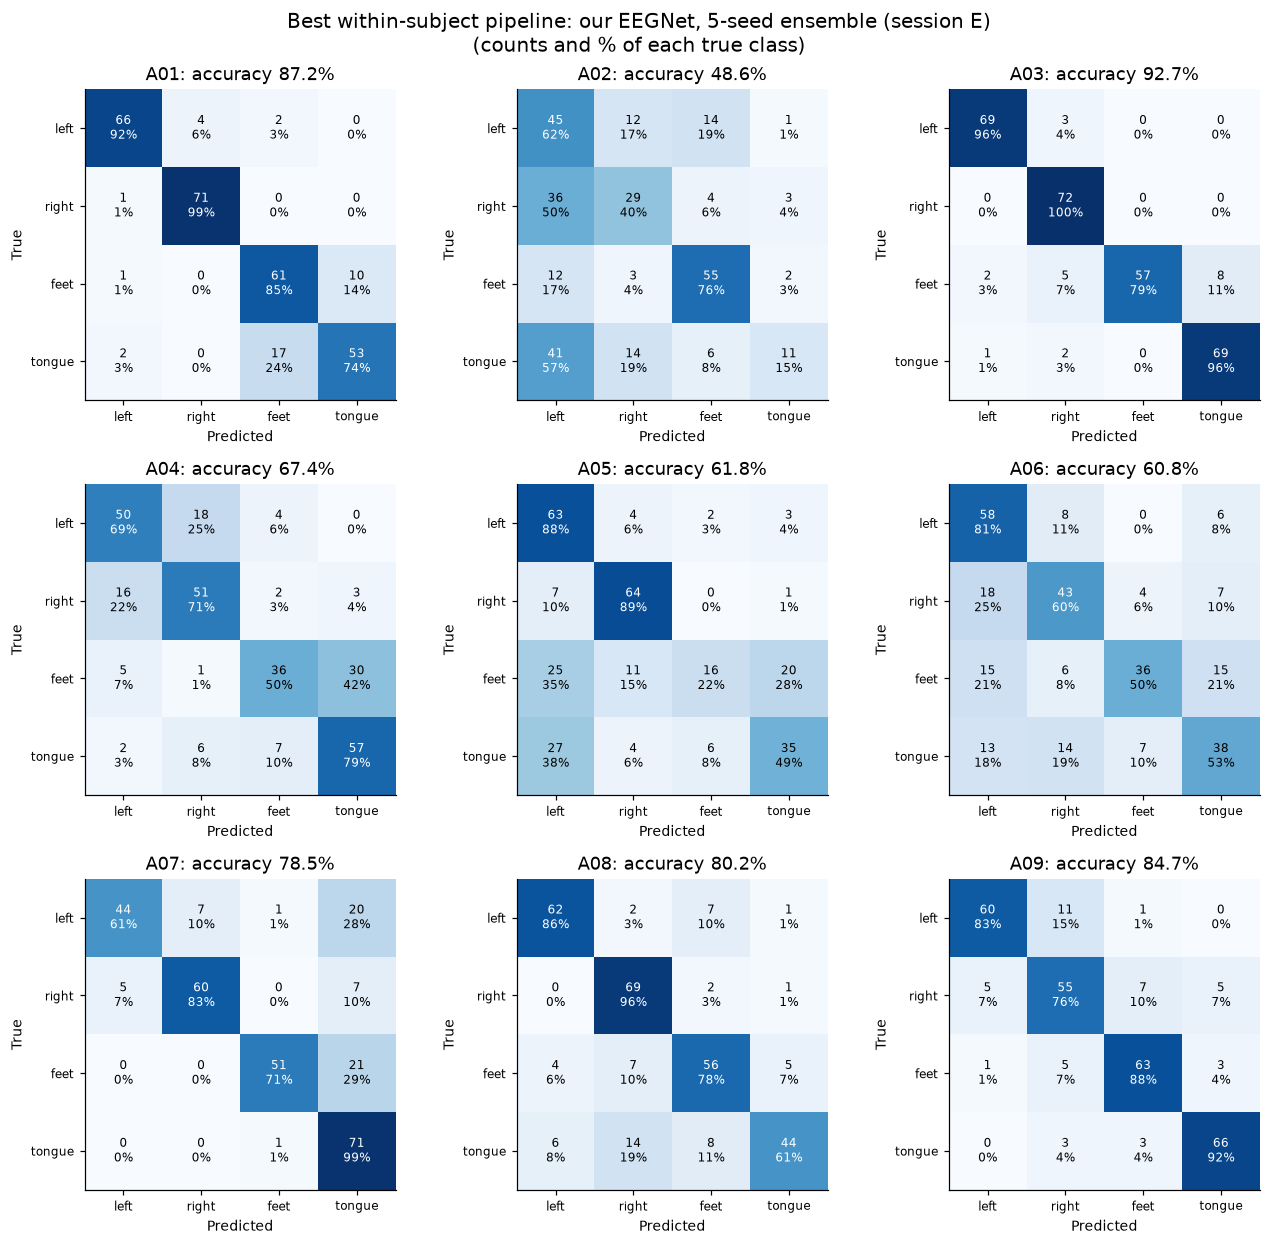

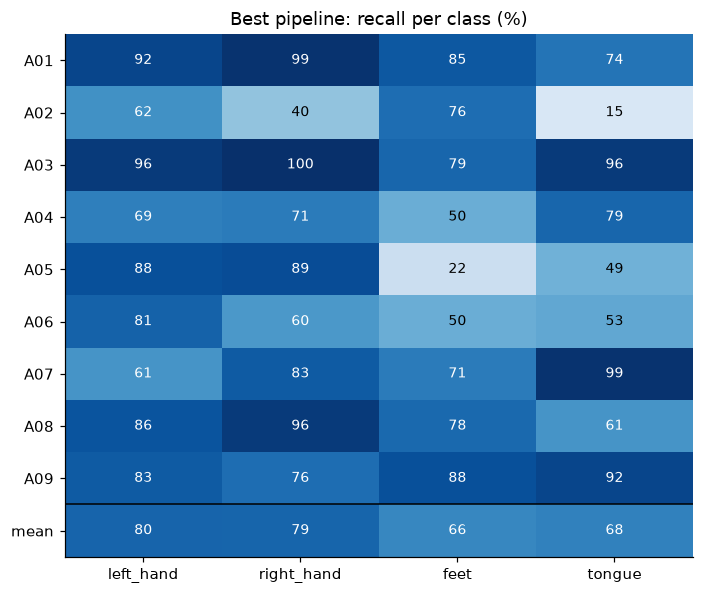

,left_hand,right_hand,feet,tongue
A01,91.7,98.6,84.7,73.6
A02,62.5,40.3,76.4,15.3
A03,95.8,100.0,79.2,95.8
A04,69.4,70.8,50.0,79.2
A05,87.5,88.9,22.2,48.6
A06,80.6,59.7,50.0,52.8
A07,61.1,83.3,70.8,98.6
A08,86.1,95.8,77.8,61.1
A09,83.3,76.4,87.5,91.7
mean,79.8,79.3,66.5,68.5


In [10]:
fin = {}
for f in sorted((ROOT / "results" / "runs" / "t2e" / "A").glob("*.json")):
    r = J(f); lg = np.array(r["logits"]); p = np.exp(lg - lg.max(1, keepdims=True)); p /= p.sum(1, keepdims=True)
    fin.setdefault(r["subject"], []).append((np.array(r["y_true"]), p))
y_true = {s: fin[s][0][0] for s in SUBJECTS}
y_ens = {s: np.mean([p for _, p in fin[s]], 0).argmax(1) for s in SUBJECTS}
plot_confusion_grid(y_true, y_ens, CLASS_NAMES, "Best within-subject pipeline: our EEGNet, 5-seed ensemble (session E)", "Blues",
                    FIG / "05_best_confusion.png"); plt.show()
rec = per_class_recall(y_true, y_ens, CLASS_NAMES)
plot_recall_heatmap(rec, "Best pipeline: recall per class (%)", "Blues", FIG / "05_best_recall.png"); plt.show()
rec

## 6. Cross-subject (unseen person)

In [11]:
lo = summary["loso"]
cs = pd.DataFrame({"EEGNet, our pipeline (notebook 04)": pd.read_csv(ROOT / "results" / "eegnet_loso_no_ea_standard.csv").groupby("subject").accuracy.mean() * 100,
                   "Her classifier (dictionary from 8 subjects)": pd.Series({s: 100 * lo["sparse"][s] for s in SUBJECTS})})
cs.loc["mean"] = cs.mean()
print("Since no EEGNet addition was kept, the final cross-subject EEGNet is our pipeline (44.66%).")
cs.round(1)

Since no EEGNet addition was kept, the final cross-subject EEGNet is our pipeline (44.66%).


,"EEGNet, our pipeline (notebook 04)",Her classifier (dictionary from 8 subjects)
A01,62.6,29.9
A02,29.9,21.9
A03,64.4,36.8
A04,36.1,25.3
A05,25.9,24.3
A06,28.6,32.3
A07,31.7,18.8
A08,62.6,37.8
A09,60.2,30.6
mean,44.7,28.6


## 7. Summary

### Every technique from the paper was implemented, verified and added to our pipeline
| Addition (chosen on session T only) | T-session CV | Session E, 1 model | Session E, 5-seed ensemble | Decision |
|---|---|---|---|---|
| **Our pipeline (EEGNet)** | 70.4% | **68.20%** | **73.53%** | baseline |
| + motor-area channels (14) | 65.7% (−4.7) | 65.21% | 69.06% | not kept |
| + her Chebyshev II filter | 67.0% (−3.4) | 65.04% | 69.25% | not kept |
| + segmentation windows (2 s, step 0.5 s) | 70.7% (+0.3) | 68.84% | 73.15% | not kept (below +0.5 rule) |
| Her classifier alone (band-pass 9 sub-bands + CSP + wavelet energy + OMP, R4) | 57.8% | 52.62% | – | – |
| **EEGNet + her classifier (fusion, weight 0.9)** | **72.2% (+1.8)** | **70.10%** | 73.07% | **kept** |

### What this means
- **Best single model: EEGNet fused with her sparse classifier, 70.10%** (+1.9 pp over our 68.20%). Her wavelet-energy features add information EEGNet misses, especially for A04 (+5.0), A08 (+2.7) and A07 (+4.2).
- **Best overall: our EEGNet as a 5-seed ensemble, 73.53%.** Adding her classifier to the ensemble does not help further (73.07%): the ensemble already captures what the fusion adds.
- **Her preprocessing steps do not help EEGNet:**
  - *Motor channel selection* removes information, since EEGNet learns its own spatial filters from all 22 channels.
  - *The Chebyshev II filter* cuts part of the 8–30 Hz band at its steep edges (strong drop for A05: 54 → 35%).
  - *Segmentation* gives the same accuracy but reaches it about 3× faster in training. That could be useful later.
- **Her classifier needs CSP on our data.** Without filtering it is at chance level. With band-pass + CSP it reaches 57.8% (CV) and 52.6% (session E), below EEGNet (68.2%).
- **Why the paper reports about 92%:** her evaluation splits *segments* randomly, so parts of the same trial are in training and testing. On our data, the same classifier scores **78.9%** with her split, **57.8%** with a split by trials, and **52.6%** on another day. The paper also used a different dataset (BCI III-IIIa: 3 subjects, 60 channels).
- **Cross-subject:** her per-subject dictionary approach does not transfer to new people (28.6%, near chance), while EEGNet reaches 44.7%. Cross-subject generalization still needs Euclidean Alignment, the next stage of the project.

### Compared with published results (Nzakuna et al. 2025, same protocol)
Our single EEGNet + her classifier (**70.10%**) is close to their single-network MCD (71.14%). Our 5-seed ensemble (**73.53%**) is between MCD and their 15-network ensemble EMCD (75.35%).

### Limitations
- One channel subset (14 channels around C3/C4) and one window length (2 s) were tested for EEGNet.
- The Chebyshev II stop-band attenuation (40 dB) is not stated in the paper and was chosen by us.
- The fusion weight was chosen on T-session CV predictions at the nearest saved epoch (450) to the final 446 epochs.
- Cross-subject sparse classification uses 4 random segments per training trial as dictionary atoms (to keep the dictionary tractable).